# Time-Integrated Plasma Modeling Tutorial

This tutorial demonstrates the LTETimeIntegrated model for time-integrated plasma simulations. The temporal evolution follows:

$$T(t) = T_f + (T_0 - T_f) \exp(-t/\tau_T), \quad n_e(t) = n_{e,f} + (n_{e,0} - n_{e,f}) \exp(-t/\tau_{n_e}), \quad L(t) = L_f + (L_0 - L_f) \exp(-t/\tau_L)$$

The model computes time-averaged spectra as a weighted sum over this evolution:
$$I_{total} = \sum_i I_i \frac{\Delta t_i}{t_{gate}}$$

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import libskit

# Enable interactive plots
%matplotlib widget

## 1. Constant Conditions Equivalence

First, let's verify that when start and end conditions are identical, the LTETimeIntegrated model produces results equivalent to the standard LTEModel.

In [ ]:
# Define common parameters
element_ratio = {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1}
temperature = 10000.0      # Temperature in Kelvin
electron_density = 1e23    # Electron density in m^-3
length = 1e-3              # Plasma length in meters
integration_time = 1e-6    # Integration time in seconds

# Create standard LTEModel
lte_model = libskit.LTEModel(element_ratio, temperature, electron_density, length)

# Create LTETimeIntegrated with constant conditions
# end = start → no temporal evolution
lte_time_constant = libskit.LTETimeIntegrated(
    element_ratio,
    temperature, temperature, 1e3,              # T_0 = T_f, tau irrelevant
    electron_density, electron_density, 1e3,    # ne_0 = ne_f
    length, length, 1e3,                        # L_0 = L_f → constant
    integration_time
)

print(f"Standard LTE: {lte_model}")
print(f"Time-integrated (constant): {lte_time_constant}")

## 2. Constant Conditions Spectral Equivalence Test

Calculate spectra from both models to verify they produce identical results when conditions don't change over time.

Maximum absolute difference: 6.16e+04
Maximum relative difference: 1.84e-10
Models are equivalent: True


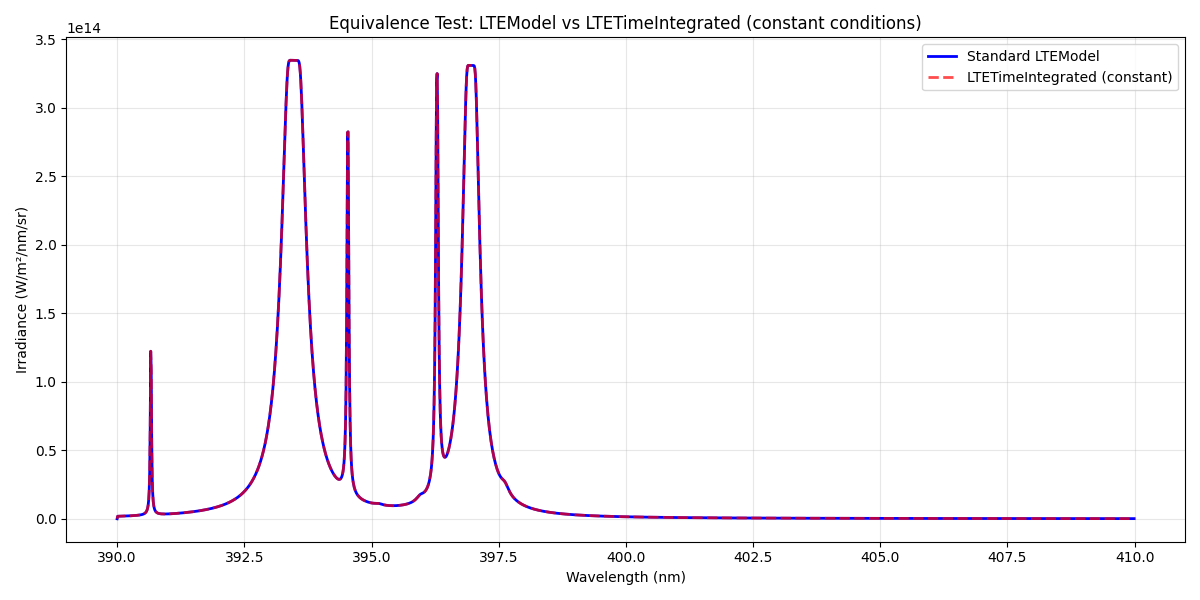

In [14]:
# Define wavelength range
wavelengths = np.arange(390, 410, 0.01)  # Ca II H&K lines region

# Calculate irradiance from both models
irradiance_lte = lte_model.calculate_irradiance(wavelengths)
irradiance_time_constant = lte_time_constant.calculate_irradiance(wavelengths)

# Check equivalence
max_difference = np.max(np.abs(irradiance_lte - irradiance_time_constant))
max_value = np.max(irradiance_lte)
relative_difference = max_difference / max_value if max_value > 0 else 0

print(f"Maximum absolute difference: {max_difference:.2e}")
print(f"Maximum relative difference: {relative_difference:.2e}")
print(f"Models are equivalent: {relative_difference < 1e-6}")

# Plot comparison
plt.figure(figsize=(12, 6))
plt.plot(wavelengths, irradiance_lte, 'b-', label='Standard LTEModel', linewidth=2)
plt.plot(wavelengths, irradiance_time_constant, 'r--', label='LTETimeIntegrated (constant)', linewidth=2, alpha=0.7)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Equivalence Test: LTEModel vs LTETimeIntegrated (constant conditions)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Temporal Evolution

The `LTETimeIntegrated` class models plasma evolution with asymptotic decay to final values:

$$T(t) = T_f + (T_0 - T_f) \exp(-t/\tau_T)$$
$$n_e(t) = n_{e,f} + (n_{e,0} - n_{e,f}) \exp(-t/\tau_{n_e})$$
$$L(t) = L_f + (L_0 - L_f) \exp(-t/\tau_L)$$

The time-integrated irradiance is computed as a weighted sum over discrete time steps.

In [ ]:
# Create time-integrated model with temporal evolution
start_temperature = 15000.0    # Initial hot temperature
end_temperature = 8000.0       # Asymptotic cooler temperature
tau_temperature = 1.59e-6      # Temperature decay time constant

start_density = 5e23           # Initial high density
end_density = 1e23             # Asymptotic lower density
tau_density = 6.21e-7          # Density decay time constant

start_length = 0.5e-3          # Initial plasma length
end_length = 2.0e-3            # Asymptotic final length
tau_length = 7e-7              # Length evolution time constant

lte_time_decay = libskit.LTETimeIntegrated(
    element_ratio,
    start_temperature, end_temperature, tau_temperature,
    start_density, end_density, tau_density,
    start_length, end_length, tau_length,
    integration_time
)

irradiance_time_constant = lte_time_decay.calculate_irradiance(wavelengths)
print(f"Time-integrated model: {lte_time_decay}")

## 4. Comparison with Instantaneous Models

The time-integrated result is NOT a simple average but a weighted sum accounting for the full temporal evolution.

In [ ]:
# Create models for comparison
lte_start = libskit.LTEModel(element_ratio, start_temperature, start_density, start_length)
lte_end = libskit.LTEModel(element_ratio, end_temperature, end_density, end_length)
lte_avg = libskit.LTEModel(
    element_ratio, 
    (start_temperature + end_temperature) / 2,
    (start_density + end_density) / 2,
    (start_length + end_length) / 2
)

# Calculate irradiances
wavelengths_broad = np.arange(390, 430, 0.1)  # Broader range for Ca lines

irradiance_start = lte_start.calculate_irradiance(wavelengths_broad)
irradiance_end = lte_end.calculate_irradiance(wavelengths_broad)
irradiance_avg = lte_avg.calculate_irradiance(wavelengths_broad)
irradiance_time_integrated = lte_time_decay.calculate_irradiance(wavelengths_broad)

# Plot comparison
plt.figure(figsize=(14, 8))
plt.plot(wavelengths_broad, irradiance_start, 'r-', label='Start conditions', linewidth=2, alpha=0.8)
plt.plot(wavelengths_broad, irradiance_end, 'b-', label='End conditions', linewidth=2, alpha=0.8)
plt.plot(wavelengths_broad, irradiance_avg, 'g--', label='Simple average', linewidth=2, alpha=0.8)
plt.plot(wavelengths_broad, irradiance_time_integrated, 'k-', label='Time-integrated', linewidth=3)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Comparison of Time-Integrated vs Instantaneous Models')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print peak intensities for comparison
print(f"Peak irradiance comparison:")
print(f"Start conditions: {np.max(irradiance_start):.2e} W/m²/nm/sr")
print(f"End conditions: {np.max(irradiance_end):.2e} W/m²/nm/sr")
print(f"Simple average: {np.max(irradiance_avg):.2e} W/m²/nm/sr")
print(f"Time-integrated: {np.max(irradiance_time_integrated):.2e} W/m²/nm/sr")

## 5. Parameter Sensitivity Analysis

Analyze how different decay rates affect the time-integrated spectrum.

In [ ]:
# Test different decay scenarios
scenarios = {
    'Fast cooling': {
        'T_start': 15000, 'T_end': 5000, 'tau_T': 0.5e-6,
        'ne_start': 5e23, 'ne_end': 5e22, 'tau_ne': 0.6e-6,
        'L_start': 0.5e-3, 'L_end': 2.0e-3, 'tau_L': 0.6e-6
    },
    'Moderate cooling': {
        'T_start': 15000, 'T_end': 5000, 'tau_T': 1.5e-6,
        'ne_start': 5e23, 'ne_end': 5e22, 'tau_ne': 0.7e-6,
        'L_start': 0.5e-3, 'L_end': 2.0e-3, 'tau_L': 0.7e-6
    },
    'Slow cooling': {
        'T_start': 15000, 'T_end': 5000, 'tau_T': 3e-6,
        'ne_start': 5e23, 'ne_end': 5e22, 'tau_ne': 0.8e-6,
        'L_start': 0.5e-3, 'L_end': 2.0e-3, 'tau_L': 0.8e-6
    }
}

wavelengths_ca = np.arange(393, 397, 0.01)  # Focus on Ca II K line

plt.figure(figsize=(12, 8))

for scenario_name, params in scenarios.items():
    model = libskit.LTETimeIntegrated(
        element_ratio,
        params['T_start'], params['T_end'], params['tau_T'],
        params['ne_start'], params['ne_end'], params['tau_ne'],
        params['L_start'], params['L_end'], params['tau_L'],
        integration_time
    )
    
    irradiance = model.calculate_irradiance(wavelengths_ca)
    plt.plot(wavelengths_ca, irradiance, label=scenario_name, linewidth=2)
    
    print(f"{scenario_name}:")
    print(f"  Temperature: {params['T_start']:.0f} → {params['T_end']:.0f} K, τ_T = {params['tau_T']*1e6:.1f} μs")
    print(f"  Density: {params['ne_start']:.1e} → {params['ne_end']:.1e} m⁻³, τ_ne = {params['tau_ne']*1e6:.1f} μs")
    print(f"  Length: {params['L_start']*1e3:.1f} mm → {params['L_end']*1e3:.1f} mm, τ_L = {params['tau_L']*1e6:.1f} μs")
    print(f"  Peak irradiance: {np.max(irradiance):.2e} W/m²/nm/sr")
    print()

plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Time-Integrated Spectra for Different Cooling Scenarios')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Integration Time (Gate Width) Dependence

The integration time $t_{gate}$ sets the observation window. Longer gates collect more total signal as the plasma evolves.

In [ ]:
# Test different integration times
integration_times = [0.5e-6, 1e-6, 2e-6, 5e-6]  # Different gate widths
wavelengths_si = np.arange(288, 292, 0.05)  # Focus on Si I line

plt.figure(figsize=(12, 8))

for t_int in integration_times:
    model = libskit.LTETimeIntegrated(
        element_ratio,
        start_temperature, end_temperature, tau_temperature,
        start_density, end_density, tau_density,
        start_length, end_length, tau_length,
        t_int
    )
    
    irradiance = model.calculate_irradiance(wavelengths_si)
    plt.plot(wavelengths_si, irradiance, label=f'{t_int*1e6:.1f} μs', linewidth=2)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Effect of Integration Time on Time-Integrated Spectrum')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()